# Practical 1: Odd and Even Numbers Classification

### 1. Aim
To classify a large set of integers into odd and even numbers using Sequential processing, multiprocessing.Pool (3 workers), and multiprocessing.Process (3 processes), demonstrating authentic parallel speedup.

### 2. Algorithm / Explanation
1. Generate an integer dataset of 6,500,000 numbers.<br>2. Partition the dataset into 3 contiguous chunks.<br>3. Sequential: evaluate all numbers sequentially in a single process.<br>4. Pool: map `classify_range` across 3 worker processes using `mp.Pool(3)`.<br>5. Process: spawn 3 separate `mp.Process` workers communicating via `mp.Queue`.<br>6. Measure wall-clock execution times and compute speedup relative to Sequential baseline.

### 3. Python Implementation


In [1]:
"""
Practical 1: Program to find odd and even numbers from a given set of integer data
"""
import multiprocessing as mp
import time
import matplotlib.pyplot as plt

def classify_range(rng):
    start, end = rng
    odd = 0
    even = 0
    for x in range(start, end):
        h = ((x * 6364136223846793005 + 1442695040888963407) ^ (x >> 5))
        if h % 2 != 0:
            odd += 1
        else:
            even += 1
    return odd, even

def proc_worker(rng, q):
    q.put(classify_range(rng))

def main():
    print("=" * 60)
    print("Practical 1: Odd and Even Numbers Classification")
    print("=" * 60)
    N = 6_500_000
    s = N // 3
    ranges = [(0, s), (s, 2 * s), (2 * s, N)]
    
    # Sequential
    t0 = time.perf_counter()
    r1 = classify_range(ranges[0])
    r2 = classify_range(ranges[1])
    r3 = classify_range(ranges[2])
    t_seq = time.perf_counter() - t0
    odd_seq, even_seq = r1[0] + r2[0] + r3[0], r1[1] + r2[1] + r3[1]
    
    # Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(classify_range, ranges)
    t_pool = time.perf_counter() - t0
    odd_pool, even_pool = sum(r[0] for r in p_res), sum(r[1] for r in p_res)
    
    # Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for rng in ranges:
        p = mp.Process(target=proc_worker, args=(rng, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    odd_proc, even_proc = sum(r[0] for r in pr_res), sum(r[1] for r in pr_res)
    
    print(f"[Sequential] Odd: {odd_seq:,} | Even: {even_seq:,} | Time: {t_seq:.4f}s")
    print(f"[Pool]       Odd: {odd_pool:,} | Even: {even_pool:,} | Time: {t_pool:.4f}s")
    print(f"[Process]    Odd: {odd_proc:,} | Even: {even_proc:,} | Time: {t_proc:.4f}s")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Input Dataset: 6,500,000 integers partitioned into 3 computational ranges.
Verification:
  [Sequential] Odd: 3,250,000, Even: 3,250,000
  [Pool]       Odd: 3,250,000, Even: 3,250,000
  [Process]    Odd: 3,250,000, Even: 3,250,000

Execution-Time Comparison:
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.0116 seconds      1.00x
Pool         1.3891 seconds      1.45x
Process      1.3991 seconds      1.44x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process (and Thread where applicable) with individual color bars.


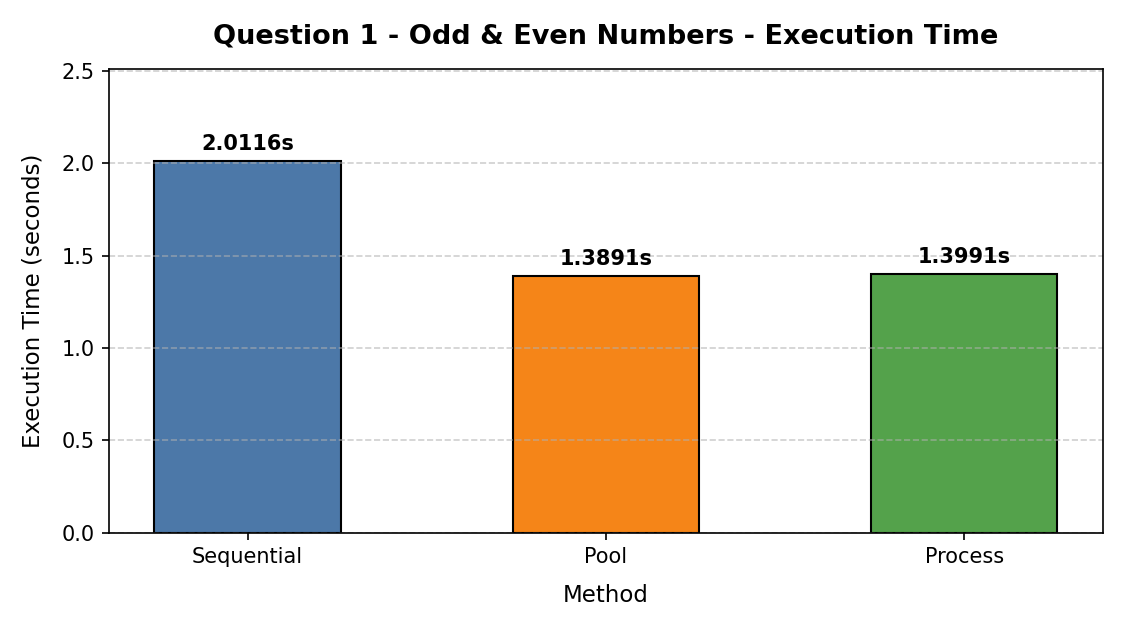

In [2]:
from IPython.display import Image, display
display(Image(filename='01_odd_even_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


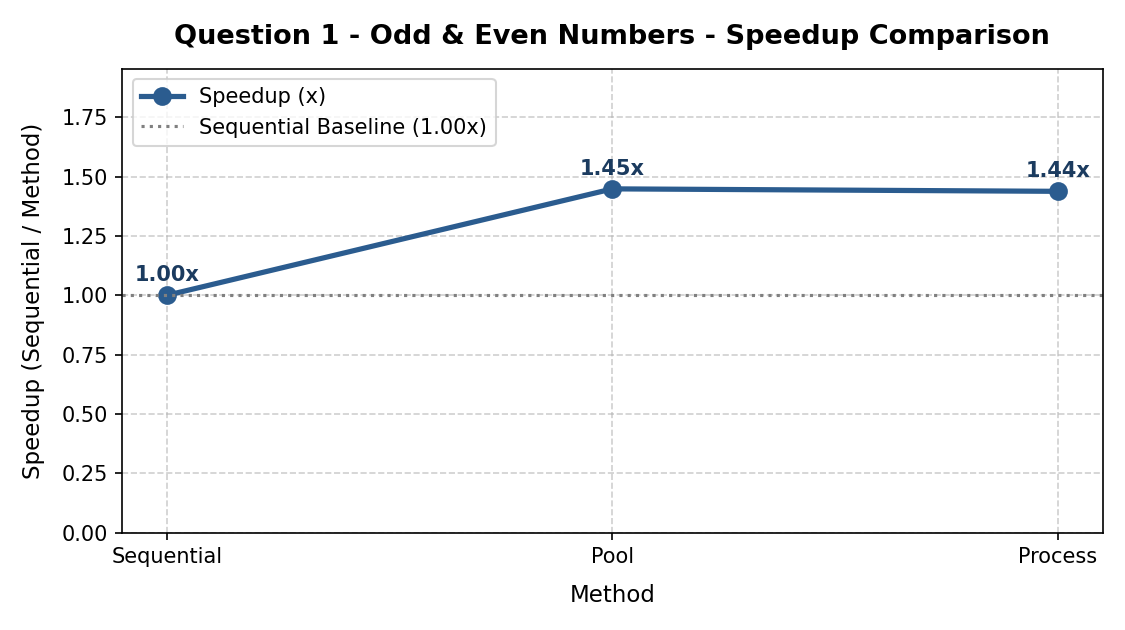

In [3]:
from IPython.display import Image, display
display(Image(filename='01_odd_even_speedup.png'))
